# Setup

In [1]:
# the camera is optional: it is started in the Images section
from webcam import grab_frame, show, start

# Intro

- https://huggingface.co/Qwen/Qwen3.5-0.8B/blob/main/config.json

# How models represent the world

## Text

In [2]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

name = "Qwen/Qwen3.5-0.8B-Base"
tok = AutoTokenizer.from_pretrained(name)
qwen = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32).to("mps").eval()

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

In [22]:
test1= "I sat on the bank of the river, then I went to the bank to withdraw cash"
test2="A colazione mangio una pesca, poi con mio padre vado a pesca"
tokens = tok.encode(test2)

ids = torch.tensor(tokens).reshape(1,-1).to("mps")
tokens

[32,
 200054,
 48509,
 789,
 4931,
 193753,
 11,
 45360,
 384,
 66677,
 58964,
 343,
 2055,
 264,
 193753]

In [23]:
print(" | ".join(tok.decode([i]) for i in tokens))

A |  colazione |  mang | io |  una |  pesca | , |  poi |  con |  mio |  padre |  v | ado |  a |  pesca


In [24]:
qwen.model.get_input_embeddings()(ids)[0].float().cpu().shape

torch.Size([15, 1024])

In [25]:
with torch.no_grad():
    h = qwen.model(input_ids=ids).last_hidden_state             
h.shape

torch.Size([1, 15, 1024])

In [ ]:
with torch.no_grad():
    e = qwen.model.get_input_embeddings()(ids)[0].float().cpu()
    h = qwen.model(input_ids=ids).last_hidden_state[0].float().cpu()


toks = [tok.decode([i]).replace("\n", "⏎") for i in ids[0].tolist()]
side = 32                                          # 32 x 32 = 1024 dimensions; 16 = only the first 256
panels = [(e, "initial embedding"), (h, f"after {len(qwen.model.layers)} layers")]

with plt.style.context("dark_background"):
    fig, axes = plt.subplots(2, len(toks), figsize=(len(toks) * 1.2, 3.4), squeeze=False,
                             gridspec_kw={"wspace": 0.1, "hspace": 0.15})
    for r, (M, label) in enumerate(panels):
        v = float(M.abs().quantile(0.98))
        for c, (t, vec) in enumerate(zip(toks, M)):
            ax = axes[r, c]
            ax.imshow(vec[: side * side].reshape(side, side), cmap="coolwarm", vmin=-v, vmax=v, interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values(): s.set_visible(False)
            if r == 0:
                ax.set_title(repr(t)[1:-1], fontsize=10, fontfamily="monospace")
        axes[r, 0].set_ylabel(label, fontsize=10)
    plt.show()

posizioni: [5, 14]


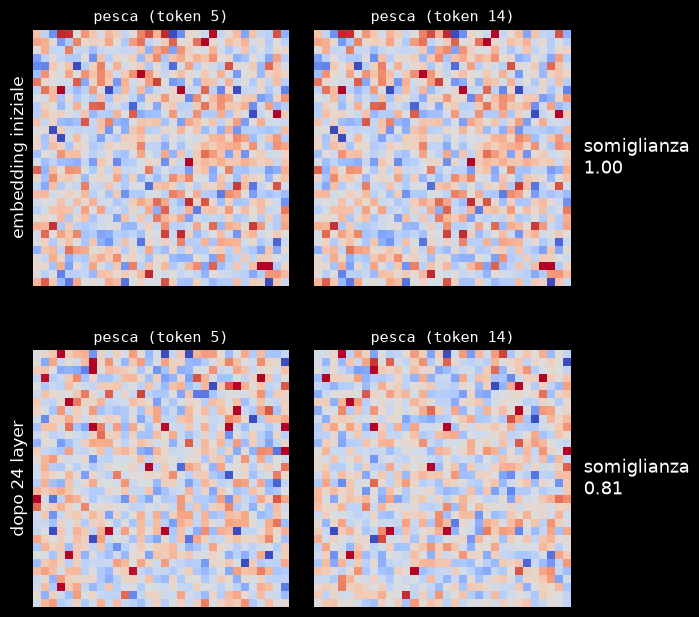

In [27]:
import torch.nn.functional as F

word = "pesca"
pos = [i for i, t in enumerate(toks) if t.strip() == word]
print("positions:", pos)
a, b = pos[:2]

with plt.style.context("dark_background"):
    fig, axes = plt.subplots(2, 2, figsize=(7, 7.5), gridspec_kw={"wspace": 0.08, "hspace": 0.25})
    for r, (M, label) in enumerate(panels):
        v = float(M.abs().quantile(0.98))
        sim = F.cosine_similarity(M[a], M[b], dim=0).item()
        for c, p in enumerate((a, b)):
            ax = axes[r, c]
            ax.imshow(M[p][: side * side].reshape(side, side), cmap="coolwarm", vmin=-v, vmax=v, interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values(): s.set_visible(False)
            ax.set_title(f"{word} (token {p})", fontsize=11, fontfamily="monospace")
        axes[r, 0].set_ylabel(label, fontsize=12)
        axes[r, 1].text(1.05, 0.5, f"similarity\n{sim:.2f}", transform=axes[r, 1].transAxes,
                        ha="left", va="center", fontsize=13)
    plt.show()

## Images

The next cells use your camera: the built-in camera of the Mac, or a phone with DroidCam. No camera? The notebook uses the example photo `data/imgs/carta_1.jpg` instead.

In [ ]:
try:
    start()   # the built-in camera of the Mac (macOS asks for permission the first time)
    # start(url="http://<phone-ip>:4747/video")   # or a phone with DroidCam: use the address the app shows
    camera = True
except RuntimeError as e:
    print(e, "\n\nNo camera: the next cells use the example photo data/imgs/carta_1.jpg")
    camera = False
show() if camera else None   # the live camera, as HTML inside the notebook

In [ ]:
from transformers import AutoImageProcessor
from PIL import Image

img = grab_frame() if camera else Image.open("data/imgs/carta_1.jpg").convert("RGB")
img

In [ ]:
proc = AutoImageProcessor.from_pretrained("Qwen/Qwen3.5-0.8B-Base")
inp = proc(images=[img], return_tensors="pt")

t, gh, gw = inp["image_grid_thw"][0].tolist()    # grid of 16x16-pixel patches
m = 2                                             # 2x2 patches become 1 token
H, W = gh * 16, gw * 16                           # size Qwen resizes the photo to
n_tok = gh * gw // (m * m)

small = img.resize((W, H))
with plt.style.context("dark_background"):
    fig, ax = plt.subplots(figsize=(8, 8 * H / W))
    ax.imshow(small)
    for y in range(0, H + 1, 16 * m): ax.axhline(y - 0.5, color="white", lw=0.8, alpha=0.7)
    for x0 in range(0, W + 1, 16 * m): ax.axvline(x0 - 0.5, color="white", lw=0.8, alpha=0.7)
    ax.set_title(f"{n_tok} tokens  ·  each square = 2x2 patches of 16 pixels", fontsize=12)
    ax.axis("off")
    plt.show()

In [ ]:
from transformers import AutoModelForImageTextToText, AutoProcessor

processor = AutoProcessor.from_pretrained(name)
qwen = AutoModelForImageTextToText.from_pretrained(name, dtype=torch.float32).to("mps").eval()

In [17]:
from PIL import Image

img = Image.open("data/imgs/carta_1.jpg").convert("RGB")
text = "<|vision_start|><|image_pad|><|vision_end|>This is a photo of"
inp = processor(text=[text], images=[img], return_tensors="pt").to("mps")

print(" | ".join(processor.tokenizer.decode([i]) for i in inp["input_ids"][0]))

<|vision_start|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|image_pad|> | <|ima

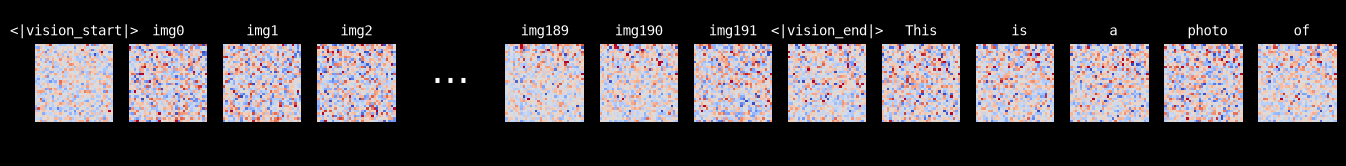

In [24]:
with torch.no_grad():
    h = qwen.model(**inp).last_hidden_state[0].float().cpu()

ids0 = inp["input_ids"][0].tolist()
img_pos = [k for k, i in enumerate(ids0) if i == qwen.config.image_token_id]
sel = list(range(img_pos[0])) + img_pos[:3] + [None] + img_pos[-3:] + list(range(img_pos[-1] + 1, len(ids0)))
v = float(h.abs().quantile(0.98))

with plt.style.context("dark_background"):
    fig, axes = plt.subplots(1, len(sel), figsize=(len(sel) * 1.2, 1.9), squeeze=False)
    for ax, k in zip(axes[0], sel):
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        if k is None:
            ax.text(0.5, 0.5, "⋯", ha="center", va="center", fontsize=28)
            continue
        ax.imshow(h[k].reshape(32, 32), cmap="coolwarm", vmin=-v, vmax=v, interpolation="nearest")
        t = f"img{img_pos.index(k)}" if k in img_pos else processor.tokenizer.decode([ids0[k]])
        ax.set_title(repr(t)[1:-1], fontsize=10, fontfamily="monospace")
    plt.show()